# 01 - Quality control
CD45+ immune cells from melanoma tumors before and after TIL adoptive cell therapy (GEO GSE221553).

The GEO matrices are the authors' post-filter cells, so this notebook (1) verifies their quality with independent per-sample metrics, (2) flags outliers by median absolute deviation (MAD), and (3) removes doublets, which the authors' filtering does not cover.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, scanpy as sc
from scipy.stats import median_abs_deviation
sc.settings.set_figure_params(dpi=100, frameon=False)
adata = sc.read_h5ad("../data/processed/cd45_raw.h5ad")
adata.layers["counts"] = adata.X.copy()
adata

AnnData object with n_obs × n_vars = 93522 × 24312
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls'
    layers: None (.X), 'counts'

## 1. Per-cell QC metrics

In [2]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")
adata.var["ribo"] = adata.var_names.str.match(r"^RP[LS]\d")
adata.var["hb"] = adata.var_names.str.match(r"^HB[AB]")
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt", "ribo", "hb"], percent_top=None, log1p=False, inplace=True)

summary = adata.obs.groupby("sample", observed=True).agg(
    patient=("patient", "first"), timepoint=("timepoint", "first"), response=("response", "first"),
    cells=("total_counts", "size"), median_umis=("total_counts", "median"),
    median_genes=("n_genes_by_counts", "median"), median_pct_mt=("pct_counts_mt", "median"),
).sort_values("cells")
summary.round(1)

,patient,timepoint,response,cells,median_umis,median_genes,median_pct_mt
sample,,,,,,,
patient5_T0,5,pre,NR,591,4211.0,1503.0,4.1
patient6_T0,6,pre,NR,1314,1658.0,849.5,1.8
patient7_T30,7,post,R,1759,2293.0,1048.0,2.9
patient10_T30,10,post,NR,2326,3149.5,1355.5,2.5
patient11_T0,11,pre,NR,2673,4179.0,1578.0,2.7
patient5_T30,5,post,NR,3413,5445.0,2179.0,4.6
patient12_T0,12,pre,NR,3567,3849.0,1337.0,3.0
patient13_T01,13,pre,R,3577,4106.0,1413.0,2.2
patient13_T02,13,pre,R,3763,4036.0,1448.0,1.4


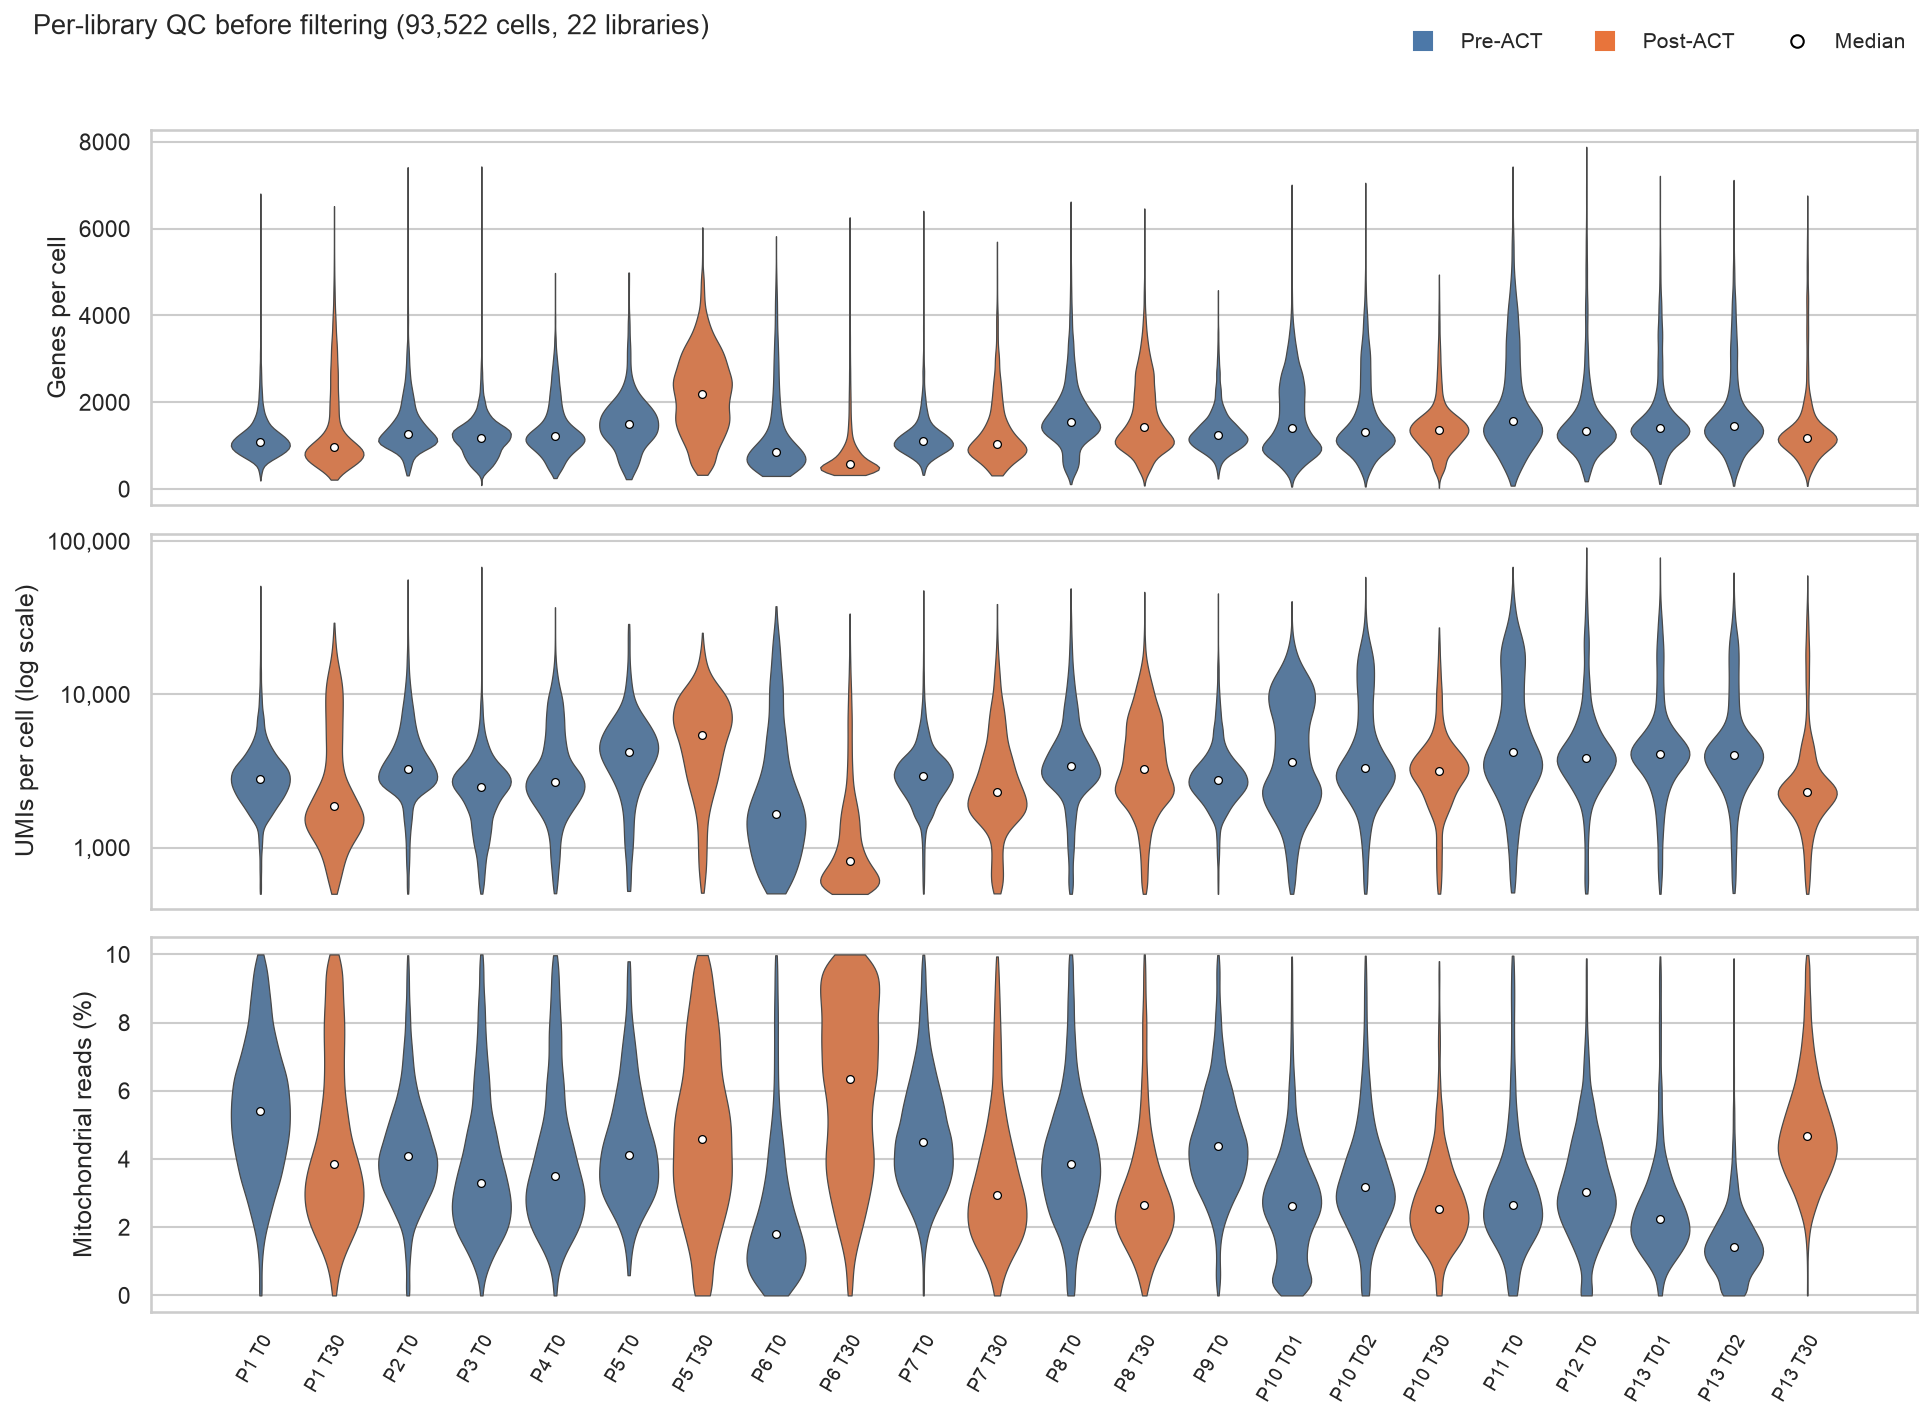

In [3]:
import re
import matplotlib.pyplot as plt, seaborn as sns

obs = adata.obs[["sample", "timepoint", "n_genes_by_counts", "total_counts", "pct_counts_mt"]].copy()
obs["sample"] = obs["sample"].astype(str)
order = sorted(obs["sample"].unique(), key=lambda s: (int(re.search(r"patient(\d+)", s).group(1)), s))
tp = obs.drop_duplicates("sample").set_index("sample")["timepoint"].astype(str)
palette = {"pre": "#4C78A8", "post": "#E8743B"}
colors = {s: palette.get(tp[s], "#999999") for s in order}
labels = [s.replace("patient", "P").replace("_", " ") for s in order]

panels = [("n_genes_by_counts", "Genes per cell", False),
          ("total_counts", "UMIs per cell (log scale)", True),
          ("pct_counts_mt", "Mitochondrial reads (%)", False)]
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 1, figsize=(13, 9.5), sharex=True)
for ax, (col, ylab, log) in zip(axes, panels):
    d = obs.copy()
    if log:
        d[col] = np.log10(d[col])
    sns.violinplot(data=d, x="sample", y=col, order=order, palette=colors, hue="sample", legend=False,
                   inner=None, cut=0, linewidth=0.6, density_norm="width", ax=ax)
    med = d.groupby("sample")[col].median().reindex(order)
    ax.scatter(range(len(order)), med.values, color="white", edgecolor="black", s=14, zorder=5, linewidth=0.6)
    if log:
        ticks = [3, 4, 5]
        ax.set_yticks(ticks); ax.set_yticklabels([f"{10**t:,.0f}" for t in ticks]); ax.set_ylim(np.log10(400), 5.05)
    ax.set_ylabel(ylab); ax.set_xlabel(""); ax.grid(axis="x", visible=False)
axes[-1].set_xticks(range(len(order)))
axes[-1].set_xticklabels(labels, rotation=60, ha="right", rotation_mode="anchor", fontsize=9)
handles = [plt.Line2D([0], [0], marker="s", ls="", color=c, markersize=9, label=k.capitalize() + "-ACT") for k, c in palette.items()]
handles.append(plt.Line2D([0], [0], marker="o", ls="", markerfacecolor="white", markeredgecolor="black", markersize=6, label="Median"))
fig.legend(handles=handles, loc="upper right", bbox_to_anchor=(0.99, 0.995), ncol=3, frameon=False, fontsize=10)
fig.suptitle(f"Per-library QC before filtering ({len(obs):,} cells, {len(order)} libraries)", fontsize=13, x=0.02, ha="left", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig("../results/figures/01_qc_violins_by_sample.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. MAD-based outlier flagging (per sample)
Following scverse best practice: a cell is flagged if log1p(total counts) or log1p(genes) is more than 5 MADs from the sample median, or if % mitochondrial counts is more than 3 MADs above the median **and** above 8%. Thresholds are computed within each sample because library depth varies between patients.

In [4]:
def mad_outlier(x, nmads):
    med, mad = np.median(x), median_abs_deviation(x)
    return (x < med - nmads * mad) | (x > med + nmads * mad)

adata.obs["outlier"] = False
for s, idx in adata.obs.groupby("sample", observed=True).indices.items():
    o = adata.obs.iloc[idx]
    flag = (mad_outlier(np.log1p(o["total_counts"]).values, 5)
            | mad_outlier(np.log1p(o["n_genes_by_counts"]).values, 5)
            | (mad_outlier(o["pct_counts_mt"].values, 3) & (o["pct_counts_mt"].values > 8)))
    adata.obs.iloc[idx, adata.obs.columns.get_loc("outlier")] = flag
print(f"MAD outliers: {adata.obs.outlier.sum()} / {adata.n_obs} ({adata.obs.outlier.mean():.1%})")
adata.obs.groupby("sample", observed=True)["outlier"].mean().mul(100).round(1).sort_values(ascending=False).head(8)

MAD outliers: 5864 / 93522 (6.3%)


sample
patient13_T30    13.8
patient13_T01    10.8
patient1_T30      9.7
patient8_T0       9.6
patient12_T0      9.2
patient7_T0       7.7
patient4_T0       7.4
patient13_T02     7.3
Name: outlier, dtype: float64

## 3. Doublet detection (Scrublet, run per sample)

In [5]:
sc.pp.scrublet(adata, batch_key="sample")
print(f"Predicted doublets: {adata.obs.predicted_doublet.sum()} ({adata.obs.predicted_doublet.mean():.1%})")
adata.obs.groupby("sample", observed=True)["predicted_doublet"].mean().mul(100).round(1).sort_values(ascending=False).head(8)

Predicted doublets: 176 (0.2%)


sample
patient5_T0      4.6
patient1_T0      2.2
patient10_T30    0.2
patient6_T0      0.2
patient11_T0     0.1
patient13_T01    0.1
patient13_T02    0.1
patient1_T30     0.1
Name: predicted_doublet, dtype: float64

## 4. Filter and save

In [6]:
keep = ~(adata.obs["outlier"] | adata.obs["predicted_doublet"])
print(f"Keeping {keep.sum()} / {adata.n_obs} cells ({keep.mean():.1%})")
adata = adata[keep].copy()
sc.pp.filter_genes(adata, min_cells=10)
print(adata)
print(adata.obs.groupby(["timepoint", "response"], observed=True).size())
adata.write_h5ad("../data/processed/cd45_qc.h5ad", compression="gzip")

Keeping 87486 / 93522 cells (93.5%)


AnnData object with n_obs × n_vars = 87486 × 23266
    obs: 'gsm', 'patient', 'sample', 'timepoint', 'biopsy_site', 'best_overall_response', 'response', 'tls', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'pct_counts_hb', 'outlier', 'n_genes', 'doublet_score', 'predicted_doublet'
    var: 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells'
    uns: 'sample_colors', 'scrublet'
    layers: None (.X), 'counts'
timepoint  response
post       NR          16803
           R           12589
pre        NR          28075
           R           30019
dtype: int64
